# 极客项目 ch08：三维立体画 Autostereogram

对应《Python Playground》第 8 章（Autosterograms）。原书 argparse/main 改为演示 cell：程序生成椭圆渐变深度图，配随机圆平铺生成立体画（墙眼观看，seed=2031）。

In [1]:
# ===== 公共设置 =====
%matplotlib inline
import os
import random
import tempfile
import numpy as np
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

random.seed(2031)
np.random.seed(2031)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False


## 书 8.3.1 重复给定的平铺图像

行列数各 +1 补齐溢出部分，超出的被画布边界裁掉。

In [2]:
# ===== 书 8.3.1 节 createTiledImage() =====
def createTiledImage(tile, dims):
    """Create a larger image of size dims by tiling the given image"""
    img = Image.new('RGB', dims)
    W, H = dims
    w, h = tile.size
    cols = int(W/w) + 1
    rows = int(H/h) + 1
    for i in range(rows):
        for j in range(cols):
            img.paste(tile, (j*w, i*h))
    return img


## 书 8.3.2 从随机圆创建平铺图像

圆半径 = 短边 1%，`-r` 让圆点留在图内，平铺接缝才干净。

In [3]:
# ===== 书 8.3.2 节 createRandomTile() =====
def createRandomTile(dims):
    """create image filled with random dots"""
    img = Image.new('RGB', dims)
    draw = ImageDraw.Draw(img)
    r = int(min(*dims)/100)  # 圆点半径为短边的 1%
    n = 1000
    for i in range(n):
        # -r 让圆点保持在图内，平铺更干净
        x, y = random.randint(0, dims[0]-r), random.randint(0, dims[1]-r)
        fill = (random.randint(0, 255), random.randint(0, 255),
                random.randint(0, 255))
        draw.ellipse((x-r, y-r, x+r, y+r), fill)
    return img


## 书 8.3.3 创建三维立体画

平铺图先铺满深度图尺寸；再对每个像素按 `深度//10` 向右搬移，把深度图编码进水平间距。

In [4]:
# ===== 书 8.3.3 节 createAutostereogram() =====
def createAutostereogram(dmap, tile):
    """Given a depth map (image) and an input image, create a new image
    with pixels shifted according to depth"""
    if dmap.mode != 'L':  # Py3：is not 'L'→!=
        dmap = dmap.convert('L')
    # 未指定贴片则用随机圆点图
    if not tile:
        tile = createRandomTile((100, 100))
    # create an image by tiling
    img = createTiledImage(tile, dmap.size)
    sImg = img.copy()
    pixD = dmap.load()
    pixS = sImg.load()
    # shift pixels output based on depth map
    cols, rows = sImg.size
    for j in range(rows):
        for i in range(cols):
            xshift = pixD[i, j]//10  # Py3：/10 得浮点不能作像素索引
            xpos = i - tile.size[0] + xshift
            if xpos > 0 and xpos < cols:
                pixS[i, j] = pixS[xpos, j]
    return sImg


## 演示：深度图 → 立体画

深度图照笔记 8.5 节实跑：椭圆径向渐变"凸起"（中心 255 最近，背景 0 最远）；平铺图由 `createRandomTile((100, 100))` 现场生成。右图放大用墙眼看，中央鼓包会浮出纸面。

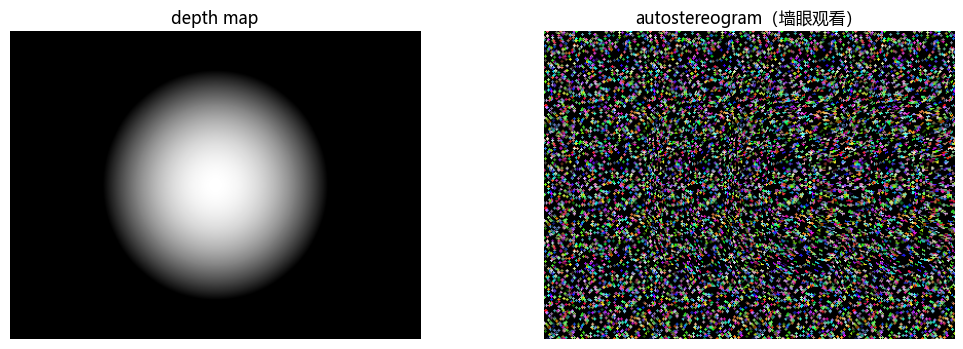

In [5]:
# ===== 演示：程序生成深度图 → 三维立体画（原 argparse/main 的替代）=====
random.seed(2031)

# 深度图：400×300，椭圆径向渐变"凸起"（中心 255 最近，边界外 0 最远）
W, H = 400, 300
xx, yy = np.meshgrid(np.linspace(-1, 1, W), np.linspace(-1, 1, H))
r2 = (xx/0.55)**2 + (yy/0.75)**2
darr = (255*np.clip(1 - r2, 0, 1)).astype(np.uint8)
dmap = Image.fromarray(darr, 'L')

tile = createRandomTile((100, 100))
asImg = createAutostereogram(dmap, tile)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].imshow(dmap, cmap='gray'); axes[0].set_title('depth map'); axes[0].axis('off')
axes[1].imshow(asImg); axes[1].set_title('autostereogram（墙眼观看）'); axes[1].axis('off')
plt.tight_layout()
plt.show()